# Model 2: K-Nearest Neighbours (KNN)

**PathSnap map matching.** Owner: Krishna Jha.

**What it is.** An instance-based classifier. It does not learn a formula. To score a candidate, it finds the **k most similar training candidates** (in the 19-feature space) and returns the share of them that were correct arcs:

$$P(\text{true arc}) = \frac{\#\{\text{correct arcs among the } k \text{ nearest training rows}\}}{k}$$

**Why we chose it for this problem**
- **No assumption about the decision boundary:** it can follow any shape, which contrasts with the linear model.
- **Fits geometric features:** every feature is geometric, so a candidate that *looks like* past correct candidates (close, same direction, connected) is probably correct, even in another country's road network.
- **A different family:** instance-based learning, as the guidelines ask for model diversity.

**Design choices**
- **Scaling is essential.** KNN measures distances between rows, so without `StandardScaler` the metre-valued features would swamp angles and flags.
- **k = 50, uniform weights.** Probabilities come in steps of 0.02, and averaging many neighbours smooths out label noise. Distance weighting would make every training row its own perfect neighbour, which makes training scores meaningless.
- **300,000-row stratified training sample.** KNN stores and searches the whole training set at prediction time. The sample keeps CV tractable with the same correct/wrong ratio. This is a stated limitation.

**Limits:** slow prediction, a large saved model (it stores the data), coarse probabilities, and sensitivity to irrelevant features.

**Configuration:** `StandardScaler` → `KNeighborsClassifier(n_neighbors=50, weights="uniform")`. There is no loss function and no training epochs ("lazy" learning).

In [1]:
import sys, os, json, time, tempfile, warnings, logging
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from IPython.display import Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay

from src import evaluate as ev, plot_style as ps
from src.config import SEED, N_FOLDS
from src.features import FEATURE_COLUMNS, load_or_build
from src.model_zoo import REGISTRY

warnings.filterwarnings("ignore", message=".*encountered in matmul")   # spurious numpy/Accelerate warning on macOS
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
ps.apply_style()
%matplotlib inline
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"sklearn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__} | seed {SEED} | folds {N_FOLDS}")

sklearn 1.7.2 | numpy 2.2.6 | pandas 2.3.3 | seed 42 | folds 5


## 1. Data

The candidate table (KKR's `python -m src.build_dataset`) has one row per (GPS fix, candidate arc within 50 m), labelled 1 if it is the correct arc. The 19 features come from `src/features.py` and use only the GPS track and the road network.

In [2]:
PROC = PROJECT_ROOT / "data" / "processed"
if not (PROC / "fixes_train.parquet").exists():
    raise FileNotFoundError("Run `python -m src.build_dataset` first.")
cand_tr, cand_te = load_or_build("train"), load_or_build("student_test")
fix_tr = pd.read_parquet(PROC / "fixes_train.parquet")
fix_te = pd.read_parquet(PROC / "fixes_student_test.parquet")

pd.DataFrame({
    "trips": [cand_tr.trip_id.nunique(), cand_te.trip_id.nunique()],
    "GPS fixes": [len(fix_tr), len(fix_te)],
    "labelled fixes": [int(fix_tr.fix_valid.sum()), int(fix_te.fix_valid.sum())],
    "candidate rows": [len(cand_tr), len(cand_te)],
    "labelled rows used for training": [int(cand_tr.fix_valid.sum()), "—"],
    "share of correct rows": [cand_tr[cand_tr.fix_valid].label.mean(), cand_te[cand_te.fix_valid].label.mean()],
}, index=["train (80 trips)", "student_test (10 trips)"])

,trips,GPS fixes,labelled fixes,candidate rows,labelled rows used for training,share of correct rows
train (80 trips),80,208417,187867,1869589,1848746,0.1002
student_test (10 trips),10,19160,19143,209579,—,0.0913


## Evaluation protocol

- **5-fold GroupKFold by trip** on the 80 train trips. A whole trip stays in one fold, because consecutive fixes are nearly identical and a row-level split would leak.
- **Preprocessing inside each fold:** the `StandardScaler` is part of the sklearn `Pipeline`, so it is fitted on the training fold only.
- **Final test:** refit on all 80 train trips, then evaluate **once** on the 10 student-test trips. Evaluator trips are never used.

| Metric | Meaning |
|---|---|
| Top-1 accuracy | Per labelled GPS fix: is the highest-scored candidate the correct arc? Fixes with no correct candidate count as wrong. |
| Macro F1, precision, recall, accuracy | On candidate rows at threshold 0.5. Macro F1 is used because only ~1 row in 9 is correct. |
| Log loss | Quality of the probabilities (lower is better). The HMM uses them as emission scores. |
| Route continuity | Share of consecutive predictions that are the same arc or directly connected. |
| Train F1 − CV F1 | A large positive gap means overfitting. |

### Reference: nearest-arc baseline
Always pick the closest candidate. No training. This is the score to beat.

In [3]:
base_cv = ev.group_cv(None, {}, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=N_FOLDS, verbose=False)
base_st = ev.baseline_metrics(cand_te, fix_te)
print(f"Nearest-arc baseline: CV Top-1 {base_cv.top1.mean():.4f} | student-test Top-1 {base_st['top1']:.4f}")

Nearest-arc baseline: CV Top-1 0.5585 | student-test Top-1 0.5381


In [4]:
def fold_plot(folds_by_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    for ax, metric, title in [(axes[0], "macro_f1", "Macro F1 per fold"), (axes[1], "top1", "Top-1 accuracy per fold")]:
        for i, (name, f) in enumerate(folds_by_name.items()):
            ax.plot(f.fold, f[metric], marker="o", ms=6, label=f"{name} (mean {f[metric].mean():.3f})",
                    color=[ps.BLUE, ps.ORANGE, ps.AQUA][i % 3])
        if metric == "top1":
            ax.plot(base_cv.fold, base_cv.top1, marker="s", ls="--", color=ps.MUTED, label=f"baseline (mean {base_cv.top1.mean():.3f})")
        ax.set(title=title, xlabel="validation fold (GroupKFold by trip)", ylim=(0.4, 1.0)); ax.set_xticks(range(N_FOLDS))
        ax.legend(loc="lower right")
    plt.show()

def st_table(rows):
    cols = ["top1", "macro_f1", "precision", "recall", "accuracy", "log_loss", "route_continuity", "candidate_miss_rate"]
    return pd.DataFrame({k: {c: v.get(c) for c in cols} for k, v in rows.items()}).T

def confusion(results):
    fig, axes = plt.subplots(1, len(results), figsize=(4.6 * len(results), 3.8))
    for ax, (name, m) in zip(np.atleast_1d(axes), results.items()):
        ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]),
                               display_labels=["wrong arc", "true arc"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",")
        ax.set_title(f"{name}: student test"); ax.grid(False)
    plt.tight_layout(); plt.show()

def calibration(probs):
    valid = cand_te.fix_valid.to_numpy()
    y = cand_te.label.to_numpy()[valid]
    fig, ax = plt.subplots(figsize=(5.2, 4.4))
    ax.plot([0, 1], [0, 1], ls="--", color=ps.MUTED, lw=1, label="perfectly calibrated")
    for i, (name, p) in enumerate(probs.items()):
        frac, mean_p = calibration_curve(y, p[valid], n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", color=[ps.BLUE, ps.ORANGE, ps.AQUA][i % 3], label=name)
    ax.set(title="Probability calibration (student test)", xlabel="predicted probability", ylabel="observed share of true arcs")
    ax.legend(loc="upper left"); plt.show()

def per_trip(prob):
    top = ev.top_candidates(cand_te, prob)
    rows = []
    for tid, f in fix_te[fix_te.fix_valid].groupby("trip_id"):
        hit = f.merge(top[top.trip_id == tid][["fix_idx", "label"]], on="fix_idx", how="left")["label"].fillna(0)
        base_top = ev.top_candidates(cand_te[cand_te.trip_id == tid], ev.baseline_scores(cand_te[cand_te.trip_id == tid]))
        base_hit = f.merge(base_top[["fix_idx", "label"]], on="fix_idx", how="left")["label"].fillna(0)
        rows.append({"trip": tid, "labelled fixes": len(f), "baseline Top-1": base_hit.mean(), "model Top-1": hit.mean()})
    d = pd.DataFrame(rows).set_index("trip")
    d["gain (points)"] = (d["model Top-1"] - d["baseline Top-1"]) * 100
    return d

def size_and_speed(model, name):
    with tempfile.TemporaryDirectory() as tmp:
        p = Path(tmp) / f"{name}.joblib"
        joblib.dump(model, p)
        mb = p.stat().st_size / 1e6
    X = cand_te[FEATURE_COLUMNS].to_numpy(float)
    t0 = time.perf_counter(); model.predict_proba(X); dt = time.perf_counter() - t0
    n_fix = cand_te[["trip_id", "fix_idx"]].drop_duplicates().shape[0]
    return {"saved size (MB)": mb, "predict time, all student-test rows (s)": dt, "ms per 1,000 fixes": dt / n_fix * 1e6}

## 2. Training: 5-fold cross-validation

In [5]:
spec = REGISTRY["knn"]
print(spec.description)
t0 = time.time()
cv = ev.group_cv(spec.factory, spec.params, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=N_FOLDS,
                 max_train_rows=spec.max_train_rows, verbose=False)
print(f"5-fold CV took {time.time() - t0:.0f}s")
cv[["fold", "n_val_trips", "macro_f1", "top1", "log_loss", "precision", "recall", "route_continuity",
    "train_macro_f1", "train_time_s", "infer_ms_per_1k_fixes"]]

StandardScaler + KNN, k=50, uniform weights, 300k-row stratified training sample


5-fold CV took 242s


,fold,n_val_trips,macro_f1,top1,log_loss,precision,recall,route_continuity,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,16,0.8998,0.8351,0.0937,0.8328,0.8012,0.9376,0.8931,0.0306,918.1606
1,1,16,0.8971,0.8415,0.1085,0.8186,0.8134,0.9323,0.8949,0.0189,778.2401
2,2,16,0.8947,0.8168,0.1060,0.8169,0.7992,0.9467,0.8950,0.0197,913.8724
3,3,16,0.8584,0.7559,0.1745,0.7736,0.7324,0.9583,0.9082,0.0271,635.3200
4,4,16,0.8936,0.8294,0.0976,0.8262,0.7850,0.9140,0.8967,0.0309,"1,002.6859"


In [6]:
pd.DataFrame({"knn (k=50)": {"CV macro F1": f"{cv.macro_f1.mean():.4f} ± {cv.macro_f1.std(ddof=1):.4f}",
                             "CV Top-1": f"{cv.top1.mean():.4f} ± {cv.top1.std(ddof=1):.4f}",
                             "CV log loss": f"{cv.log_loss.mean():.4f}",
                             "train macro F1": f"{cv.train_macro_f1.mean():.4f}",
                             "train − CV macro F1": f"{cv.train_macro_f1.mean() - cv.macro_f1.mean():+.4f}"}}).T

,CV macro F1,CV Top-1,CV log loss,train macro F1,train − CV macro F1
knn (k=50),0.8887 ± 0.0171,0.8157 ± 0.0347,0.1161,0.8976,+0.0088


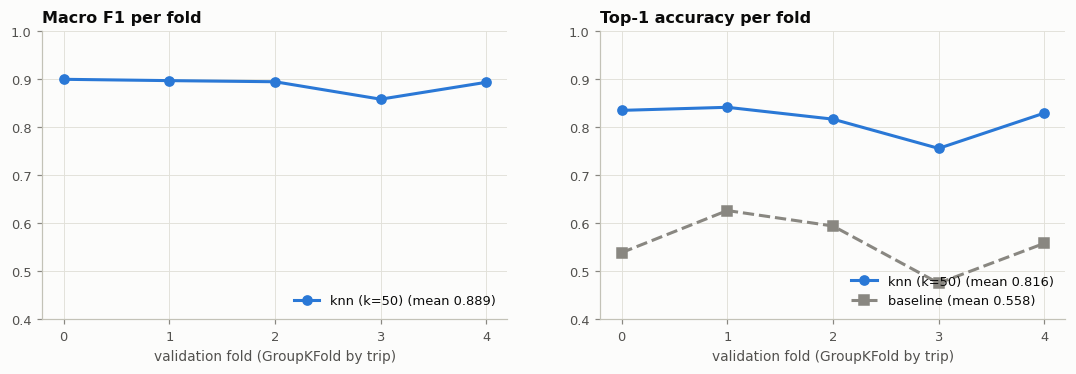

In [7]:
fold_plot({"knn (k=50)": cv})

## 3. Testing on the 10 student-test trips
Refit on all 80 train trips (300k-row stratified sample), then evaluate once.

In [8]:
model, prob, fit_s, pred_s = ev.fit_predict(spec.factory, spec.params, cand_tr, cand_te, FEATURE_COLUMNS, spec.max_train_rows)
st = ev.evaluate_predictions(cand_te, prob, fix_te)
print(f"fit on {spec.max_train_rows:,} rows in {fit_s:.1f}s, predicted {len(cand_te):,} rows in {pred_s:.1f}s")
st_table({"nearest-arc baseline": base_st, "knn (k=50)": st})

fit on 300,000 rows in 0.0s, predicted 209,579 rows in 17.7s


,top1,macro_f1,precision,recall,accuracy,log_loss,route_continuity,candidate_miss_rate
nearest-arc baseline,0.5381,0.7459,0.5381,0.5383,0.9156,NaN,0.8210,0.0005
knn (k=50),0.8287,0.8953,0.8172,0.8020,0.9655,0.0928,0.9356,0.0005


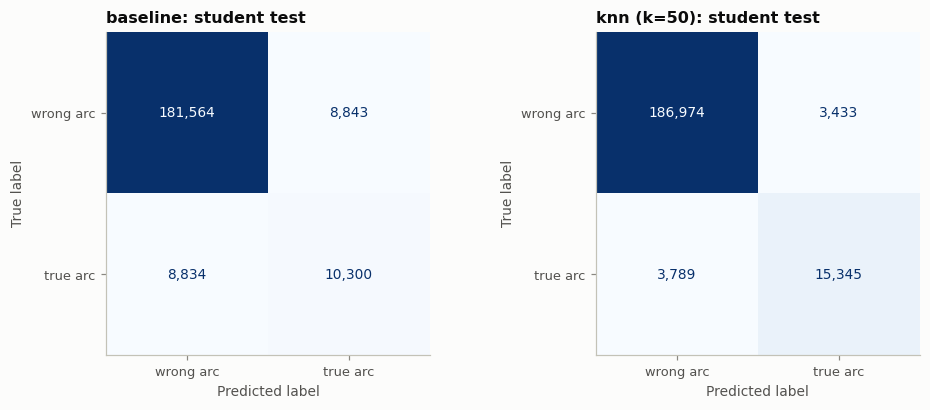

In [9]:
confusion({"baseline": base_st, "knn (k=50)": st})

## 4. Choosing k (train partition only)
A sensitivity check: 3-fold GroupKFold on the train trips with a 100k-row training sample per fold. Student-test data is not used to choose k.

In [10]:
from src.model_zoo import make_knn
sens = []
for k in [10, 25, 50, 100]:
    f = ev.group_cv(make_knn, {"n_neighbors": k}, cand_tr, fix_tr, FEATURE_COLUMNS, n_folds=3, max_train_rows=100_000, verbose=False)
    sens.append({"k": k, "CV Top-1": f.top1.mean(), "CV macro F1": f.macro_f1.mean(), "CV log loss": f.log_loss.mean(),
                 "train macro F1": f.train_macro_f1.mean()})
sens = pd.DataFrame(sens); sens

,k,CV Top-1,CV macro F1,CV log loss,train macro F1
0,10,0.7983,0.8787,0.1692,0.8995
1,25,0.7982,0.8782,0.1344,0.8907
2,50,0.7954,0.8771,0.1232,0.8853
3,100,0.7907,0.8726,0.1186,0.8788


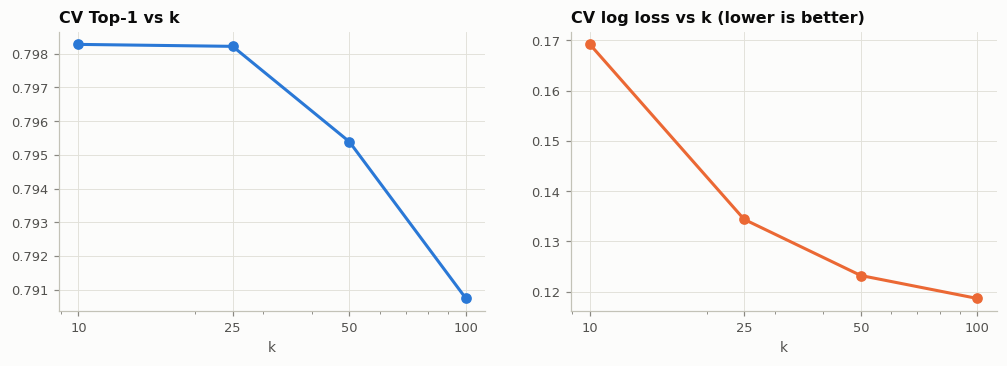

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(sens.k, sens["CV Top-1"], marker="o", color=ps.BLUE); axes[0].set(title="CV Top-1 vs k", xlabel="k")
axes[1].plot(sens.k, sens["CV log loss"], marker="o", color=ps.ORANGE); axes[1].set(title="CV log loss vs k (lower is better)", xlabel="k")
for a in axes: a.set_xscale("log"); a.set_xticks(sens.k, sens.k)
plt.show()

Top-1 barely changes across k, while log loss improves as k grows (smoother probabilities). Small k also shows a larger train-vs-CV gap, the classic sign of overfitting. **k = 50** balances accuracy, probability quality and cost.

## 5. Probability quality
Points on the dashed line mean well-calibrated probabilities, which is what the HMM needs.

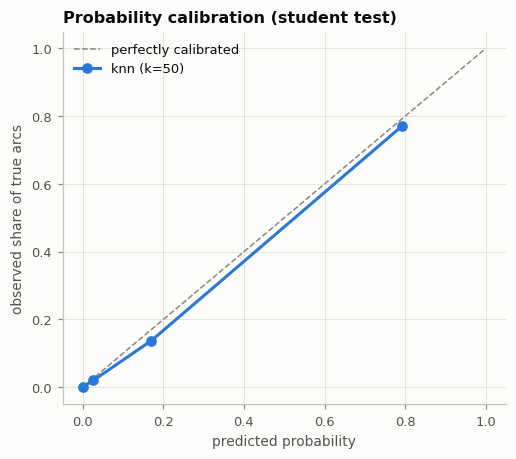

In [12]:
calibration({"knn (k=50)": prob})

## 6. Accuracy per student-test trip

In [13]:
trips = per_trip(prob); trips

,labelled fixes,baseline Top-1,model Top-1,gain (points)
trip,,,,
00000000,2503,0.5374,0.9161,37.8746
00000007,1354,0.4749,0.8951,42.0236
00000009,1049,0.5310,0.8236,29.2660
00000040,2995,0.5396,0.9012,36.1603
00000052,262,0.7710,0.9198,14.8855
00000056,3941,0.6907,0.8538,16.3157
00000065,768,0.6927,0.7969,10.4167
00000076,1486,0.4112,0.7974,38.6272
00000077,3911,0.4050,0.6873,28.2281


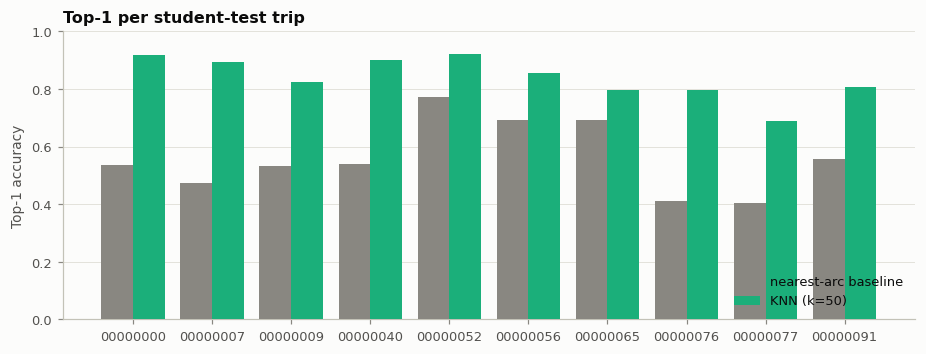

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(trips))
ax.bar(x - 0.2, trips["baseline Top-1"], 0.4, color=ps.MUTED, label="nearest-arc baseline", zorder=3)
ax.bar(x + 0.2, trips["model Top-1"], 0.4, color=ps.AQUA, label="KNN (k=50)", zorder=3)
ax.set_xticks(x, trips.index); ax.set(ylim=(0, 1), ylabel="Top-1 accuracy", title="Top-1 per student-test trip")
ax.legend(loc="lower right"); ax.grid(axis="x", visible=False); plt.show()

## 7. Model size and speed
KNN stores its training data, so the saved model is large and prediction means searching it.

In [15]:
pd.DataFrame({"knn (k=50)": size_and_speed(model, "knn")}).T

,saved size (MB),"predict time, all student-test rows (s)","ms per 1,000 fixes"
knn (k=50),48.0017,17.6757,922.5311


## 8. Summary (generated from the numbers above)

In [16]:
b = base_st["top1"]
best_k = sens.loc[sens["CV Top-1"].idxmax(), "k"]
lines = [f"- **Baseline** (nearest arc): {b:.1%} Top-1 on student test.",
         f"- **KNN (k=50)**: student-test Top-1 **{st['top1']:.1%}** ({(st['top1'] - b) * 100:+.1f} points vs baseline), "
         f"macro F1 {st['macro_f1']:.3f}, log loss {st['log_loss']:.3f}; CV Top-1 {cv.top1.mean():.1%} ± {cv.top1.std(ddof=1):.1%}; "
         f"train − CV F1 gap {cv.train_macro_f1.mean() - cv.macro_f1.mean():+.3f}.",
         f"- **k sensitivity:** Top-1 ranges {sens['CV Top-1'].min():.1%}–{sens['CV Top-1'].max():.1%} over k = 10–100 (best k = {best_k}); "
         f"log loss improves from {sens['CV log loss'].iloc[0]:.3f} (k=10) to {sens['CV log loss'].iloc[-1]:.3f} (k=100).",
         f"- **Cost:** {cv.infer_ms_per_1k_fixes.mean():.0f} ms per 1,000 fixes in CV. That is slow for a live demo compared with linear models.",
         f"- **Upper bound** from candidate misses: {1 - base_st['candidate_miss_rate']:.2%} Top-1."]
display(Markdown("\n".join(lines)))

- **Baseline** (nearest arc): 53.8% Top-1 on student test.
- **KNN (k=50)**: student-test Top-1 **82.9%** (+29.1 points vs baseline), macro F1 0.895, log loss 0.093; CV Top-1 81.6% ± 3.5%; train − CV F1 gap +0.009.
- **k sensitivity:** Top-1 ranges 79.1%–79.8% over k = 10–100 (best k = 10); log loss improves from 0.169 (k=10) to 0.119 (k=100).
- **Cost:** 850 ms per 1,000 fixes in CV. That is slow for a live demo compared with linear models.
- **Upper bound** from candidate misses: 99.95% Top-1.